### 1. 定义
官方推荐了三种定义Schema的方式：TypedDict、dataclass、Pydantic

1.1 TypedDict

{'logs': ['node_1 运行完成', 'node_2 运行完成'], 'cur_id': 'start，node_1，node_2'}


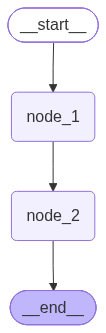

In [6]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add
from IPython.display import display

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    cur_id: str

def node_1(state: OverAllState) -> OverAllState:
    pre_id = state["cur_id"]
    return {
        "logs": ["node_1 运行完成"],
        "cur_id": pre_id + "，node_1",
    }

def node_2(state: OverAllState) -> OverAllState:
    pre_id = state["cur_id"]
    return {
        "logs": ["node_2 运行完成"],
        "cur_id": pre_id + "，node_2",
    }

builder = StateGraph(state_schema=OverAllState)
# 添加节点
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
# 添加边
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)

graph = builder.compile()

result = graph.invoke({"cur_id": "start"})
print(result)

display(graph)

1.2. dataclass

{'logs': ['node_1 运行完毕', 'node_2 运行完毕'], 'cur_id': 'start，node_1，node_2'}


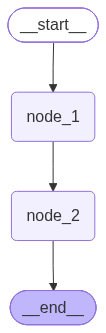

In [8]:
from langgraph.graph import StateGraph, START, END
from typing import Annotated
from dataclasses import dataclass
from operator import add
from IPython.display import display

@dataclass
class OverAllState:
    logs: Annotated[list[str], add]
    cur_id: str

def node_1(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {
        "logs": ["node_1 运行完毕"],
        "cur_id": pre_id + "，node_1",
    }

def node_2(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {
        "logs": ["node_2 运行完毕"],
        "cur_id": pre_id + "，node_2",
    }

builder = StateGraph(state_schema=OverAllState)

builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)

builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)

graph = builder.compile()

result = graph.invoke({"cur_id": "start"})
print(result)

display(graph)

1.3. Pydantic

{'logs': ['node_1 运行完成', 'node_2 运行完成'], 'cur_id': 'start，node_1，node_2'}


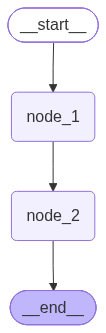

In [9]:
from langgraph.graph import StateGraph, START, END
from typing import Annotated
from pydantic import BaseModel
from operator import add
from IPython.display import display

class OverAllState(BaseModel):
    logs: Annotated[list[str], add]
    cur_id: str

def node_1(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {
        "logs": ["node_1 运行完成"],
        "cur_id": pre_id + "，node_1",
    }

def node_2(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {
        "logs": ["node_2 运行完成"],
        "cur_id": pre_id + "，node_2",
    }
# 3.1 创建图， 获取建造者
builder = StateGraph(state_schema=OverAllState)

builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)

builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)

graph = builder.compile()

result = graph.invoke({"cur_id": "start"})
print(result)
display(graph)


### 2. State Reducer
State Reducer 是 LangGraph 中用于合并状态更新的核心机制。在 LangGraph 的 `StateGraph` 中，每个节点可以读取和写入共享状态，而 Reducer 定义了如何将多个节点对同一状态键的更新合并。
Reducer 的核心特征：
- 函数签名：`(Value, Value) -> Value`，接收当前值和更新值，返回合并后的新值
- 注解定义：通过 `Annotated[Type, reducer_function]` 为状态键指定 Reducer
- 默认行为：未指定 Reducer 的状态键使用覆盖策略（Last-Write-Wins）

2.1. 定义Reducer函数

In [10]:
def my_reducer(left: list[str], right: list[str]) -> list[str]:
    return left + right

left = ['a', 'b']
right = ['c']

print(my_reducer(left, right))


['a', 'b', 'c']


参数说明：

- `left`：状态中已有的消息列表；
- `right`：当前节点返回的消息更新值；
- `format`：可选参数，用于指定返回消息的格式，通常无需手动设置。

`left` 与 `right` 的类型均为 `Messages`。`Messages` 可以理解为 LangChain 消息对象的列表，其中每个元素都是 `BaseMessage` 或其子类的实例，常见子类包括：

- `HumanMessage`：用户的输入消息；
- `AIMessage`：AI 的回复消息；
- `SystemMessage`：系统提示消息；
- `ToolMessage`：工具调用的结果消息。

`add_messages` 处理的是对话消息序列，而非普通的字符串列表。

`BaseMessage` 包含一个可选的 `id` 属性，用于唯一标识一条消息。`add_messages` 在合并 `left` 与 `right` 时，不是简单地执行列表拼接，而是依据消息的 `id` 进行合并：

- 若 `right` 中的某条消息的 `id` 在 `left` 中不存在，则将该消息追加到结果列表末尾；
- 若 `right` 中的某条消息的 `id` 与 `left` 中已有消息的 `id` 相同，则使用 `right` 中的新消息替换 `left` 中的旧消息。

因此，`add_messages` 的作用可以概括为：在保留历史消息的基础上追加新消息，并允许通过相同的消息 `id` 覆盖已有消息。

需要特别说明，`add_messages` 并非简单地对 `left` 与 `right` 求“并集”。更准确地说，它是一个基于消息 `id` 的消息列表合并函数：既支持追加新消息，也支持更新已有消息。

In [12]:
from langgraph.graph.message import add_messages
from langchain.messages import HumanMessage, AIMessage, SystemMessage

left_msg = [
    SystemMessage(content="你是个善解人意的助手", id="1"),
    HumanMessage(content="你好", id="2"),
    AIMessage(content="你好~", id="3"),
]

right_msg = [
 HumanMessage(content="我是老王，你是小王", id="2"),
 AIMessage(content="好的，我记住啦", id="3"),
 HumanMessage(content="你是谁？", id="4"),
 AIMessage(content="我是小王", id="1"),
]

merged = add_messages(left_msg, right_msg)

for msg in merged:
 print(msg)



content='我是小王' additional_kwargs={} response_metadata={} id='1' tool_calls=[] invalid_tool_calls=[]
content='我是老王，你是小王' additional_kwargs={} response_metadata={} id='2'
content='好的，我记住啦' additional_kwargs={} response_metadata={} id='3' tool_calls=[] invalid_tool_calls=[]
content='你是谁？' additional_kwargs={} response_metadata={} id='4'


如果某个 State 字段没有显式定义 `Reducer`，LangGraph 会使用默认的状态更新行为：后一次更新值会覆盖该字段原有的状态值。

{'logs': ['node_b'], 'id': 'node_b'}
==============================  --> result <--  ==============================


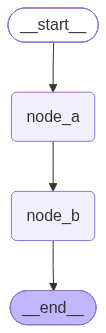

In [14]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

class OverAllState(TypedDict):
    logs: list[str]
    id: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "logs": ["node_a"],
        "id": "node_a",
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "logs": ["node_b"],
        "id": "node_b",
    }

builder = StateGraph(state_schema=OverAllState)

builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()

result = graph.invoke({"logs":["START"], "id":"start"})
print(result)
print("=" * 30, " --> result <-- ", "=" * 30)
display(graph)


### 3. 节点中访问State
3.1. 图节点中读取State

In [17]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict,Annotated
from operator import add

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str

def node_a(state: OverAllState) -> OverAllState:
    for k,v in state.items():
        print(f"node_a ==> k = {k}, v = {v}")

def node_b(state: OverAllState) -> OverAllState:
    for k,v in state.items():
        print(f"node_b ==> k = {k}, v = {v}")

builder = StateGraph(state_schema=OverAllState)

builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()

result = graph.invoke({"logs":["START"], "id":"start-hello-world"})
print("=" * 30, " --> result <-- ", "=" * 30)
print(result)

node_a ==> k = logs, v = ['START']
node_a ==> k = id, v = start-hello-world
node_b ==> k = logs, v = ['START']
node_b ==> k = id, v = start-hello-world
==============================  --> result <--  ==============================
{'logs': ['START'], 'id': 'start-hello-world'}


3.2. 图节点更新State

In [18]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    # 如果有并行的节点，一定要采用 Reducer的方法, 否则会报错
    # id: Annotated[str, add]
    id: str

def node_a(state: OverAllState) -> OverAllState:
    for k,v in state.items():
        print(f"node_a ==> k = {k}, v = {v}")
    return {
        "logs": ["node_a 更新状态"],
        "id": "node_a 更新",
    }

def node_b(state: OverAllState) -> OverAllState:
    for k,v in state.items():
        print(f"node_b ==> k = {k}, v = {v}")

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"logs":["START"], "id":"start-boy"})
print("=" * 30, " --> result <-- ", "=" * 30)
print(result)


node_a ==> k = logs, v = ['START']
node_a ==> k = id, v = start-boy
node_b ==> k = logs, v = ['START', 'node_a 更新状态']
node_b ==> k = id, v = node_a 更新
==============================  --> result <--  ==============================
{'logs': ['START', 'node_a 更新状态'], 'id': 'node_a 更新'}


3.3. Overwrite绕过Reducer

In [27]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add
from langgraph.types import Overwrite

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str

def node_a(state: OverAllState) -> OverAllState:
    for k,v in state.items():
        print(f"node_a ==> k = {k}, v = {v}")
    return {
        "logs": ["node_a"],
        "id": "node_a",
    }

def node_b(state: OverAllState) -> OverAllState:
    for k,v in state.items():
        print(f"node_b ==> k = {k}, v = {v}")
    return {
        "logs": Overwrite(["node_b"]),
        "id": "node_b",
    }

def node_c(state: OverAllState) -> OverAllState:
    for k,v in state.items():
        print(f"node_c ==> k = {k}, v = {v}")
    return {
        "logs": ["node_c"],
        "id": "node_c",
    }

builder = StateGraph(state_schema=OverAllState)

builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", "node_c")
builder.add_edge("node_c", END)

graph = builder.compile()
result = graph.invoke({"logs":["START"], "id":"start"})
print("=" * 30, " --> result <-- ", "=" * 30)
print(result)

node_a ==> k = logs, v = ['START']
node_a ==> k = id, v = start
node_b ==> k = logs, v = ['START', 'node_a']
node_b ==> k = id, v = node_a
node_c ==> k = logs, v = ['node_b']
node_c ==> k = id, v = node_b
==============================  --> result <--  ==============================
{'logs': ['node_b', 'node_c'], 'id': 'node_c'}
